In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()  # asumiendo que abres Jupyter en la raíz del repo

sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "py_modules"))

from pipeline_config import MAPS_DIR, FIGS_DIR
import results_comp

In [2]:
import numpy as np
#import seaborn as sns
from matplotlib import pyplot as plt


In [3]:
def load_gstools_sigE_results(
    results_comp,
    maps_dir,
    *,
    model_order=("exponential", "gaussian", "stable"),
    sigE_levels=(0, 1, 2),
    r_by_model=None,
    grid_size=256,
    spatial_bin=0,
    read_header=True,
    fit_key="fit",
):
    """
    Load GSTools fit results for different correlation models
    and emissivity fluctuation levels.

    Expected filenames include:

        gstools_finite_sigE0_exponential_r11_N256_bin0
        gstools_finite_sigE1_exponential_r11_N256_bin0
        gstools_finite_sigE2_exponential_r11_N256_bin0
        gstools_finite_sigE0_gaussian_r13_N256_bin0
        gstools_finite_sigE1_gaussian_r13_N256_bin0
        gstools_finite_sigE2_gaussian_r13_N256_bin0

    Temporary correspondence with the original notebook:

        entry["line"] -> correlation model
        entry["bin"]  -> sigE level
    """

    if r_by_model is None:
        r_by_model = {
            "exponential": 11,
            "gaussian": 13,
        }

    data_in = []

    for model in model_order:
        if model not in r_by_model:
            raise KeyError(
                f"No r value was provided for model {model!r}."
            )

        r_value = r_by_model[model]

        for sigE_level in sigE_levels:
            file_name = (
                f"gstools_finite_sigE{sigE_level}_"
                f"{model}_r{r_value}_"
                f"N{grid_size}_bin{spatial_bin}"
            )

            internal_name = f"{model}_sigE{sigE_level}"

            bundle = results_comp.load_line_bundle_mat_ideal(
                file_name,
                internal_name,
                maps_dir,
                read_header=read_header,
            )

            fit = bundle[fit_key]
            fit_dict = fit.to_dict(orient="list")

            # Ensure that the expected three parameters exist
            expected_params = {"sig2", "r0", "m"}
            missing_params = expected_params.difference(fit_dict)

            if missing_params:
                raise KeyError(
                    f"{file_name} is missing the parameters: "
                    f"{sorted(missing_params)}"
                )

            entry = {
                # Temporary keys for compatibility with the old plotter
                "line": model,
                "bin": sigE_level,

                # Semantically correct keys for future generalization
                "model": model,
                "sigE": sigE_level,

                "label": f"{model}_sigE{sigE_level}",
                "file_name": file_name,
                "bundle": bundle,
                "fit": fit,
                "fit_dict": fit_dict,
                "meta": bundle.get("meta", {}),
            }

            data_in.append(entry)

    return data_in

In [4]:
data_in = load_gstools_sigE_results(
    results_comp,
    MAPS_DIR,
    model_order=("exponential", "gaussian", "stable"),
    sigE_levels=(0, 1, 2),
    r_by_model={
        "exponential": 11,
        "gaussian": 13,
        "stable": 12,
    },
    grid_size=256,
    spatial_bin=0,
    read_header=True,
)

In [5]:
len(data_in)

9

In [6]:
for entry in data_in:
    print(
        entry["model"],
        entry["sigE"],
        entry["file_name"],
        list(entry["fit_dict"]),
    )

exponential 0 gstools_finite_sigE0_exponential_r11_N256_bin0 ['sig2', 'r0', 'm']
exponential 1 gstools_finite_sigE1_exponential_r11_N256_bin0 ['sig2', 'r0', 'm']
exponential 2 gstools_finite_sigE2_exponential_r11_N256_bin0 ['sig2', 'r0', 'm']
gaussian 0 gstools_finite_sigE0_gaussian_r13_N256_bin0 ['sig2', 'r0', 'm']
gaussian 1 gstools_finite_sigE1_gaussian_r13_N256_bin0 ['sig2', 'r0', 'm']
gaussian 2 gstools_finite_sigE2_gaussian_r13_N256_bin0 ['sig2', 'r0', 'm']
stable 0 gstools_finite_sigE0_stable_r12_N256_bin0 ['sig2', 'r0', 'm']
stable 1 gstools_finite_sigE1_stable_r12_N256_bin0 ['sig2', 'r0', 'm']
stable 2 gstools_finite_sigE2_stable_r12_N256_bin0 ['sig2', 'r0', 'm']


In [7]:
data_in[0]["fit"]

,sig2,r0,m
0,0.095622,19.270088,1.506099
1,0.003296,0.891370,0.027762
2,0.003154,0.817996,0.027348


In [8]:
data_in[0]["fit_dict"]

{'sig2': [0.09562223338806916, 0.0032963676204065956, 0.0031542321818261165],
 'r0': [19.270088220339083, 0.8913696118728005, 0.817996275996073],
 'm': [1.5060990150445326, 0.02776200271847218, 0.02734805283366315]}

In [9]:
from pathlib import Path
from astropy.io import fits


def extract_model_references(
    data_in,
    maps_dir,
    *,
    model_order=("exponential", "gaussian"),
    file_extension=".fits",
):
    """
    Read M3D, L_SCALE, and R0 from one FITS file per model.
    """

    header_keys = ("SIG2", "M3D", "L_SCALE", "R0")
    references = {}

    maps_dir = Path(maps_dir)

    for model in model_order:

        # Select the first available sigE sample for this model
        try:
            entry = next(
                entry
                for entry in data_in
                if entry["model"] == model
            )
        except StopIteration:
            raise ValueError(
                f"No entry was found for model {model!r}."
            )

        file_path = maps_dir / (
            entry["file_name"] + file_extension
        )

        if not file_path.exists():
            raise FileNotFoundError(
                f"FITS file not found:\n{file_path}"
            )

        # Read only the primary header
        header = fits.getheader(
            file_path,
            ext=0,
        )

        missing_keys = [
            key
            for key in header_keys
            if key not in header
        ]

        if missing_keys:
            raise KeyError(
                f"The primary header of {file_path.name!r} "
                f"is missing: {missing_keys}"
            )


        references[model] = {
            "SIG2": float(header["SIG2"]),
            "M3D": float(header["M3D"]),
            "L_SCALE": float(header["L_SCALE"]),
            "R0": float(header["R0"]),
            "source_file": file_path.name,            
        }

    return references

In [10]:
model_references = extract_model_references(
    data_in,
    MAPS_DIR,
    model_order=("exponential", "gaussian"),
)

In [11]:
model_references

{'exponential': {'SIG2': 0.08766628880932227,
  'M3D': 1.0,
  'L_SCALE': 16.0,
  'R0': 11.090354888959125,
  'source_file': 'gstools_finite_sigE0_exponential_r11_N256_bin0.fits'},
 'gaussian': {'SIG2': 0.09139385848479922,
  'M3D': 2.0,
  'L_SCALE': 16.0,
  'R0': 13.320873778523163,
  'source_file': 'gstools_finite_sigE0_gaussian_r13_N256_bin0.fits'}}

In [12]:
def extract_model_references(
    data_in,
    maps_dir,
    *,
    model_order=("exponential", "gaussian"),
    file_extension=".fits",
    check_consistency=True,
):
    """
    Extract reference values from the FITS primary headers.

    M3D, L_SCALE, and R0 are model-level values.

    SIG2 is read separately for every combination of:
        model × sigE level
    """

    from pathlib import Path

    import numpy as np
    from astropy.io import fits

    maps_dir = Path(maps_dir)

    model_header_keys = (
        "M3D",
        "L_SCALE",
        "R0",
    )

    references = {}

    for model in model_order:
        model_entries = sorted(
            (
                entry
                for entry in data_in
                if entry["model"] == model
            ),
            key=lambda entry: entry["sigE"],
        )

        if len(model_entries) == 0:
            raise ValueError(
                f"No entries were found for model {model!r}."
            )

        model_reference = None
        sig2_by_sigE = {}

        for entry in model_entries:
            file_path = maps_dir / (
                entry["file_name"] + file_extension
            )

            if not file_path.exists():
                raise FileNotFoundError(
                    f"FITS file not found:\n{file_path}"
                )

            header = fits.getheader(
                file_path,
                ext=0,
            )

            required_keys = (
                "SIG2",
                "M3D",
                "L_SCALE",
                "R0",
            )

            missing_keys = [
                key
                for key in required_keys
                if key not in header
            ]

            if missing_keys:
                raise KeyError(
                    f"The primary header of {file_path.name!r} "
                    f"is missing: {missing_keys}"
                )

            sigE_level = entry["sigE"]

            # Sample-specific SIG2
            sig2_by_sigE[sigE_level] = float(
                header["SIG2"]
            )

            current_model_reference = {
                "M3D": float(header["M3D"]),
                "L_SCALE": float(header["L_SCALE"]),
                "R0": float(header["R0"]),
            }

            # Use the first file for model-level references
            if model_reference is None:
                model_reference = current_model_reference

            # Confirm that model-level references are consistent
            elif check_consistency:
                for key in model_header_keys:
                    if not np.isclose(
                        current_model_reference[key],
                        model_reference[key],
                    ):
                        raise ValueError(
                            f"Inconsistent {key} for model "
                            f"{model!r} in file "
                            f"{file_path.name!r}."
                        )

        references[model] = {
            **model_reference,
            "SIG2_BY_SIGE": sig2_by_sigE,
        }

    return references

In [13]:
model_references = extract_model_references(
    data_in,
    MAPS_DIR,
    model_order=("exponential", "stable","gaussian"),
)

In [14]:
def plot_gstools_params_sigE(
    data_in,
    *,
    params=("sig2", "r0", "m"),
    model_order=("exponential", "gaussian"),
    sigE_levels=(0, 1, 2),
    model_references=None,
    xtick_labels=None,
    param_labels=None,
    param_titles=None,
    param_ylims=None,
    decimals=4,
    figsize=(15, 4.5),
    color_palette="Greys_d",
    markers=("o", "s"),
    jitter=0.06,
    capsize=4,
    elinewidth=1.8,
    markersize=8,
    reference_linewidth=1.8,
    reference_halfwidth=0.12,
    show_values=False,
    save=False,
    savepath="gstools_fit_parameters.pdf",
):
    """
    Plot GSTools fit parameters as a function of sigE level.

    Fit results
    -----------
    Each data_in entry must contain:

        entry["model"]
        entry["sigE"]
        entry["fit_dict"]

    where:

        fit_dict[param] = [
            value,
            upper_uncertainty,
            lower_uncertainty,
        ]

    Reference values
    ----------------
    SIG2:
        One value for every model × sigE sample. It is plotted as
        a short horizontal segment at the corresponding x-position.

    L_SCALE:
        One value per model. It is plotted as a solid horizontal
        line in the r0 panel.

    R0:
        One value per model. It is plotted as a dotted horizontal
        line in the r0 panel.

    M3D:
        One value per model. It is plotted as a solid horizontal
        line in the m panel.

    Expected model_references format
    --------------------------------
    {
        "exponential": {
            "M3D": value,
            "L_SCALE": value,
            "R0": value,
            "SIG2_BY_SIGE": {
                0: value,
                1: value,
                2: value,
            },
        },
        "gaussian": {
            "M3D": value,
            "L_SCALE": value,
            "R0": value,
            "SIG2_BY_SIGE": {
                0: value,
                1: value,
                2: value,
            },
        },
    }
    """

    import numpy as np
    import seaborn as sns
    from matplotlib import pyplot as plt
    from matplotlib.lines import Line2D

    if len(data_in) == 0:
        raise ValueError("data_in is empty.")

    if len(params) == 0:
        raise ValueError("params is empty.")

    # ------------------------------------------------------------
    # Colors and markers
    # ------------------------------------------------------------
    colors = sns.color_palette(
        color_palette,
        n_colors=len(model_order),
    )[::-1]

    color_map = {
        model: colors[i]
        for i, model in enumerate(model_order)
    }

    marker_map = {
        model: markers[i % len(markers)]
        for i, model in enumerate(model_order)
    }

    # Horizontal offsets to prevent overlapping points
    if len(model_order) > 1:
        jitter_offsets = np.linspace(
            -jitter,
            jitter,
            len(model_order),
        )
    else:
        jitter_offsets = np.array([0.0])

    jitter_map = {
        model: jitter_offsets[i]
        for i, model in enumerate(model_order)
    }

    # ------------------------------------------------------------
    # X-axis labels
    # ------------------------------------------------------------
    if xtick_labels is None:
        xtick_labels_final = [
            f"sigE{level}"
            for level in sigE_levels
        ]

    elif isinstance(xtick_labels, dict):
        xtick_labels_final = [
            xtick_labels.get(level, str(level))
            for level in sigE_levels
        ]

    elif isinstance(xtick_labels, (list, tuple)):
        if len(xtick_labels) != len(sigE_levels):
            raise ValueError(
                "xtick_labels must have the same length "
                "as sigE_levels."
            )

        xtick_labels_final = list(xtick_labels)

    else:
        raise TypeError(
            "xtick_labels must be None, a dictionary, "
            "a list, or a tuple."
        )

    # ------------------------------------------------------------
    # Parameter labels and titles
    # ------------------------------------------------------------
    default_param_labels = {
        "sig2": r"$\sigma^2$",
        "r0": r"$r_0$",
        "m": r"$m$",
    }

    default_param_titles = {
        "sig2": r"$\sigma^2$ vs $\mathrm{sigE}$",
        "r0": r"$r_0$ vs $\mathrm{sigE}$",
        "m": r"$m$ vs $\mathrm{sigE}$",
    }

    param_labels_final = {
        **default_param_labels,
        **(param_labels or {}),
    }

    param_titles_final = {
        **default_param_titles,
        **(param_titles or {}),
    }

    if param_ylims is None:
        param_ylims = {}

    elif not isinstance(param_ylims, dict):
        raise TypeError(
            "param_ylims must be None or a dictionary."
        )

    # ------------------------------------------------------------
    # Build lookup table
    # lookup[(model, sigE)] = fit_dict
    # ------------------------------------------------------------
    lookup = {
        (
            entry["model"],
            entry["sigE"],
        ): entry["fit_dict"]
        for entry in data_in
    }

    # ------------------------------------------------------------
    # Figure
    # ------------------------------------------------------------
    fig, axes = plt.subplots(
        1,
        len(params),
        figsize=figsize,
        sharex=True,
        squeeze=False,
    )

    axes = axes.ravel()

    # ------------------------------------------------------------
    # Main plotting loop
    # ------------------------------------------------------------
    for ax, param in zip(axes, params):

        # --------------------------------------------------------
        # Fit results and confidence intervals
        # --------------------------------------------------------
        for model in model_order:
            x_values = []
            y_values = []
            yerr_lower = []
            yerr_upper = []

            for sigE_level in sigE_levels:
                key = (
                    model,
                    sigE_level,
                )

                if key not in lookup:
                    continue

                fit_dict = lookup[key]

                if param not in fit_dict:
                    continue

                value = round(
                    float(fit_dict[param][0]),
                    decimals,
                )

                upper = max(
                    0.0,
                    round(
                        float(fit_dict[param][1]),
                        decimals,
                    ),
                )

                lower = max(
                    0.0,
                    round(
                        float(fit_dict[param][2]),
                        decimals,
                    ),
                )

                x_values.append(
                    sigE_level + jitter_map[model]
                )

                y_values.append(value)
                yerr_lower.append(lower)
                yerr_upper.append(upper)

            if len(x_values) == 0:
                continue

            ax.errorbar(
                x_values,
                y_values,
                yerr=[
                    yerr_lower,
                    yerr_upper,
                ],
                fmt=marker_map[model],
                color=color_map[model],
                markerfacecolor=color_map[model],
                markeredgecolor="black",
                markeredgewidth=0.6,
                markersize=markersize,
                capsize=capsize,
                elinewidth=elinewidth,
                linestyle="none",
                label=model.capitalize(),
                zorder=3,
            )

            if show_values:
                for x, y in zip(x_values, y_values):
                    ax.text(
                        x,
                        y,
                        f"{y:.{decimals}f}",
                        ha="center",
                        va="bottom",
                        fontsize=8,
                    )

        # --------------------------------------------------------
        # Reference values from the FITS headers
        # --------------------------------------------------------
        if model_references is not None:

            for model in model_order:
                if model not in model_references:
                    continue

                references = model_references[model]

                # ------------------------------------------------
                # Sample-specific SIG2 reference values
                # ------------------------------------------------
                if param == "sig2":
                    sig2_by_sigE = references.get(
                        "SIG2_BY_SIGE",
                        {},
                    )

                    for sigE_level in sigE_levels:
                        if sigE_level not in sig2_by_sigE:
                            continue

                        x_reference = (
                            sigE_level
                            + jitter_map[model]
                        )

                        y_reference = sig2_by_sigE[
                            sigE_level
                        ]

                        ax.hlines(
                            y=y_reference,
                            xmin=(
                                x_reference
                                - reference_halfwidth
                            ),
                            xmax=(
                                x_reference
                                + reference_halfwidth
                            ),
                            color=color_map[model],
                            linestyle="-",
                            linewidth=reference_linewidth,
                            alpha=0.9,
                            zorder=2,
                        )

                # ------------------------------------------------
                # Model-level r0 reference values
                # ------------------------------------------------
                elif param == "r0":

                    if "L_SCALE" in references:
                        ax.axhline(
                            references["L_SCALE"],
                            color=color_map[model],
                            linestyle="-",
                            linewidth=reference_linewidth,
                            alpha=0.85,
                            zorder=1,
                        )

                    if "R0" in references:
                        ax.axhline(
                            references["R0"],
                            color=color_map[model],
                            linestyle=":",
                            linewidth=reference_linewidth,
                            alpha=0.85,
                            zorder=1,
                        )

                # ------------------------------------------------
                # Model-level m reference value
                # ------------------------------------------------
                elif param == "m":

                    if "M3D" in references:
                        ax.axhline(
                            references["M3D"],
                            color=color_map[model],
                            linestyle="-",
                            linewidth=reference_linewidth,
                            alpha=0.85,
                            zorder=1,
                        )

        # --------------------------------------------------------
        # Titles and axes
        # --------------------------------------------------------
        ax.set_title(
            param_titles_final.get(param, param)
        )

        ax.set_ylabel(
            param_labels_final.get(param, param)
        )

        ax.set_xlabel(r"$\mathrm{sigE}$ level")

        ax.set_xticks(sigE_levels)
        ax.set_xticklabels(xtick_labels_final)

        ax.set_xlim(
            min(sigE_levels) - 0.4,
            max(sigE_levels) + 0.4,
        )

        if param in param_ylims:
            ax.set_ylim(param_ylims[param])

        ax.grid(alpha=0.3)

        # --------------------------------------------------------
        # Reference-line legends
        # --------------------------------------------------------
        if model_references is not None:

            if param == "sig2":
                reference_handles = [
                    Line2D(
                        [0],
                        [0],
                        color="black",
                        linestyle="-",
                        linewidth=reference_linewidth,
                        label=r"Input $\sigma^2$",
                    ),
                ]

                ax.legend(
                    handles=reference_handles,
                    loc="best",
                    frameon=False,
                    fontsize=10,
                )

            elif param == "r0":
                reference_handles = [
                    Line2D(
                        [0],
                        [0],
                        color="black",
                        linestyle="-",
                        linewidth=reference_linewidth,
                        label="L_SCALE",
                    ),
                    Line2D(
                        [0],
                        [0],
                        color="black",
                        linestyle=":",
                        linewidth=reference_linewidth,
                        label="R0",
                    ),
                ]

                ax.legend(
                    handles=reference_handles,
                    loc="best",
                    frameon=False,
                    fontsize=10,
                )

            elif param == "m":
                reference_handles = [
                    Line2D(
                        [0],
                        [0],
                        color="black",
                        linestyle="-",
                        linewidth=reference_linewidth,
                        label="M3D",
                    ),
                ]

                ax.legend(
                    handles=reference_handles,
                    loc="best",
                    frameon=False,
                    fontsize=10,
                )

    # ------------------------------------------------------------
    # Common legend for correlation models
    # ------------------------------------------------------------
    model_handles = [
        Line2D(
            [0],
            [0],
            marker=marker_map[model],
            color="none",
            markerfacecolor=color_map[model],
            markeredgecolor="black",
            markeredgewidth=0.6,
            markersize=markersize,
            linestyle="none",
            label=model.capitalize(),
        )
        for model in model_order
    ]

    fig.legend(
        handles=model_handles,
        title="Correlation model",
        loc="upper center",
        bbox_to_anchor=(0.5, 1.08),
        ncol=len(model_order),
        frameon=False,
    )

    fig.tight_layout(
        rect=[0, 0, 1, 0.92]
    )

    if save:
        fig.savefig(
            savepath,
            bbox_inches="tight",
        )

    return fig, axes

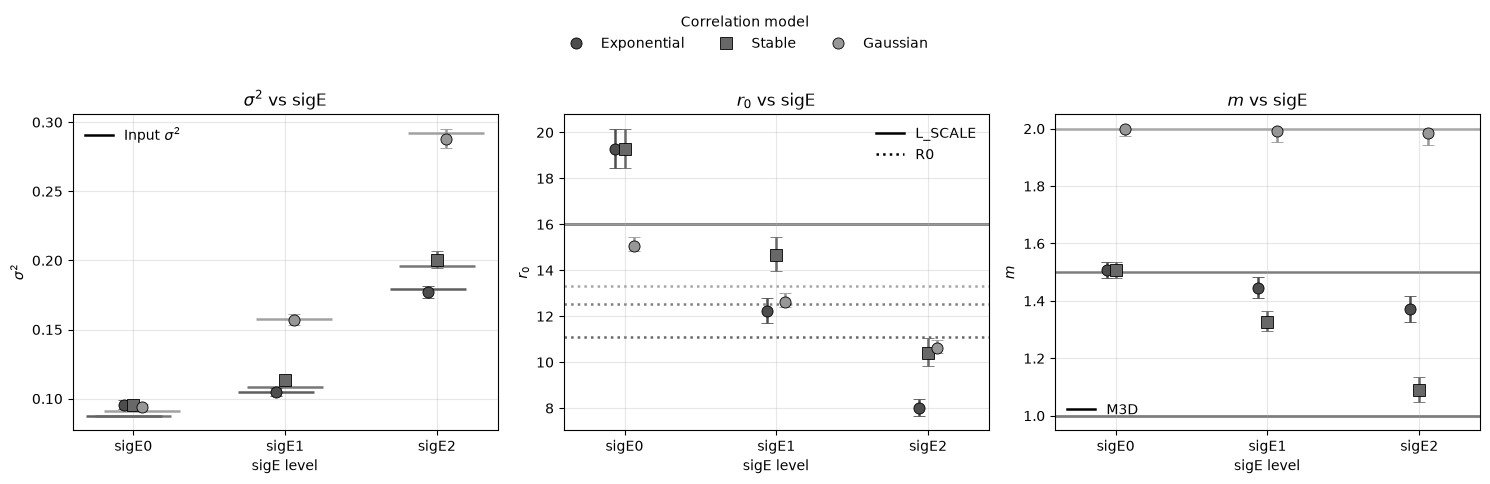

In [15]:
fig, axes = plot_gstools_params_sigE(
    data_in,
    params=("sig2", "r0", "m"),
    model_order=("exponential", "stable", "gaussian"),
    sigE_levels=(0, 1, 2),
    model_references=model_references,
    figsize=(15, 4.5),
    markersize=8,
    jitter=0.06,
    reference_halfwidth=0.25,
    save=False,
)